# Лабораторная работа №1

«Анализ и прогнозирование временных рядов на примере розничных продаж»

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pywt
from scipy import signal, stats
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.gofplots import qqplot
from IPython.display import display, Markdown

from analysis.modeling import (
    fit_model,
    metrics,
    select_models,
    horizon_quality,
    supported_horizon,
)

# Общий вид графиков и таблиц, чтобы результаты было удобно сравнивать.
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 1. Знакомство с данными
Сначала проверю даты, пропуски и значения признаков. `SalesAmount` - объём продаж; денежная единица в файле не указана. `Promotion` отмечает месяцы с акцией, `HolidayMonth` - праздничные месяцы. Сам по себе рост продаж в месяц акции ещё не доказывает, что его вызвала акция.

In [2]:
# Ошибки исходного файла не исправляем молча: сначала проверяем структуру ряда.
data = pd.read_csv(Path("retail_sales_mock_data.csv"), parse_dates=["Date"])

checks = pd.Series(
    {
        "Строк": len(data),
        "Повторов дат": data.Date.duplicated().sum(),
        "Пропущенных значений": data.isna().sum().sum(),
        "Неположительных продаж": (data.SalesAmount <= 0).sum(),
    }
)

display(checks.to_frame("Результат"), data.head())

assert not data.Date.duplicated().any() and not data.isna().any().any()
assert (data.SalesAmount > 0).all()
assert data[["Promotion", "HolidayMonth"]].isin([0, 1]).all().all()

data = data.sort_values("Date").set_index("Date")
assert data.index.equals(pd.date_range(data.index.min(), data.index.max(), freq="MS"))

data = data.asfreq("MS")
y = data.SalesAmount.astype(float)
x = data[["Promotion", "HolidayMonth"]].astype(float)

display(data.describe())

,Результат
Строк,48
Повторов дат,0
Пропущенных значений,0
Неположительных продаж,0


,Date,SalesAmount,Promotion,HolidayMonth
0,2020-01-01,12248,0,0
1,2020-02-01,13011,0,0
2,2020-03-01,12722,0,0
3,2020-04-01,14030,1,0
4,2020-05-01,7783,0,0


,SalesAmount,Promotion,HolidayMonth
count,48.000,48.000,48.000
mean,"11,768.542",0.125,0.083
std,"2,257.545",0.334,0.279
min,"7,783.000",0.000,0.000
25%,"10,219.750",0.000,0.000
50%,"11,851.000",0.000,0.000
75%,"13,014.000",0.000,0.000
max,"17,996.000",1.000,1.000


### Как разделены данные
Последние 12 месяцев (2023 год) оставляю для окончательной проверки. Подбор параметров использует только 2020-2022 годы: обучение заканчивается после 24, 27 и 30 месяцев, а прогноз каждый раз строится до конца 2022 года. Это три проверки с постепенно растущей историей, без перемешивания дат.

Чтобы даже выбор сезонности не подглядывал в проверочные продажи, графики и декомпозиции ниже относятся к первым 24 месяцам. Общая таблица выше служит только проверкой исходного файла.

,Часть,Начало,Конец,Месяцев
0,Первичный анализ,2020-01-01,2021-12-01,24
1,Обучение перед тестом,2020-01-01,2022-12-01,36
2,Тест,2023-01-01,2023-12-01,12


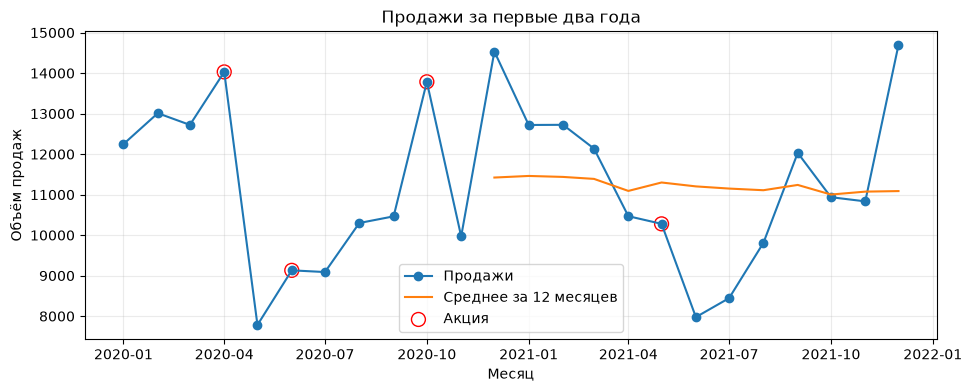

In [3]:
# Два полных года дают минимальную историю для годовой декомпозиции.
explore = data.iloc[:24]
series = explore.SalesAmount.astype(float)
train, test = y.iloc[:36], y.iloc[36:]

display(
    pd.DataFrame(
        {
            "Часть": ["Первичный анализ", "Обучение перед тестом", "Тест"],
            "Начало": [series.index.min(), train.index.min(), test.index.min()],
            "Конец": [series.index.max(), train.index.max(), test.index.max()],
            "Месяцев": [len(series), len(train), len(test)],
        }
    )
)

fig, ax = plt.subplots()
ax.plot(series.index, series, marker="o", label="Продажи")
ax.plot(series.rolling(12).mean(), label="Среднее за 12 месяцев")

mask = explore.Promotion.eq(1)
ax.scatter(
    series.index[mask],
    series[mask],
    s=100,
    facecolors="none",
    edgecolors="red",
    label="Акция",
)

ax.set(title="Продажи за первые два года", ylabel="Объём продаж", xlabel="Месяц")
ax.legend()
plt.show()

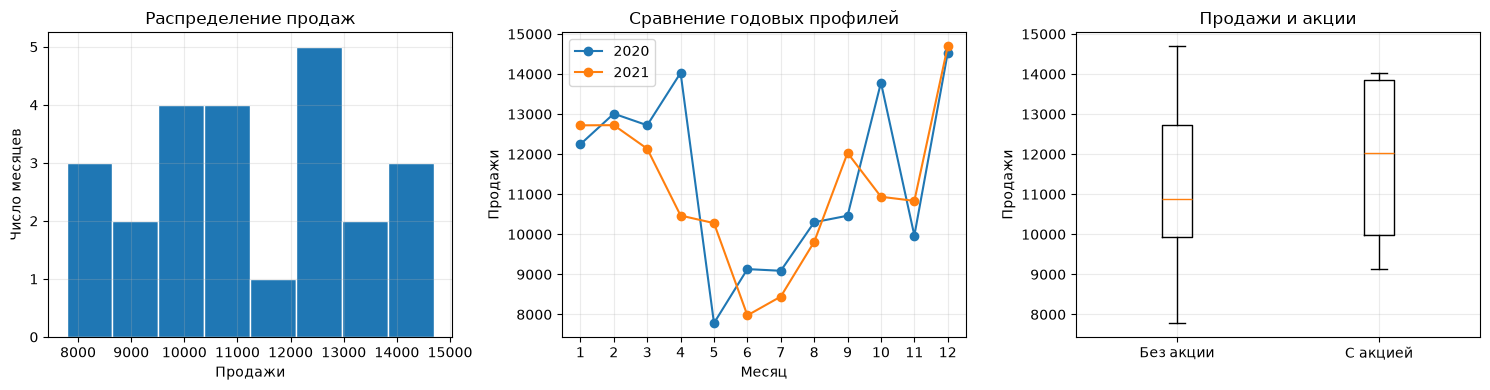

,count,mean,std
Promotion,,,
0,20,"11,144.850","1,997.701"
1,4,"11,806.500","2,473.454"


In [4]:
# Разные виды графиков показывают распределение и календарный рисунок.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(series, bins=8, edgecolor="white")
axes[0].set(title="Распределение продаж", xlabel="Продажи", ylabel="Число месяцев")

monthly = explore.assign(month=explore.index.month, year=explore.index.year)
for year, group in monthly.groupby("year"):
    axes[1].plot(group.month, group.SalesAmount, marker="o", label=str(year))

axes[1].set(
    title="Сравнение годовых профилей",
    xlabel="Месяц",
    ylabel="Продажи",
    xticks=range(1, 13),
)
axes[1].legend()

axes[2].boxplot(
    [explore.loc[explore.Promotion.eq(v), "SalesAmount"] for v in [0, 1]],
    tick_labels=["Без акции", "С акцией"],
)
axes[2].set(title="Продажи и акции", ylabel="Продажи")

plt.tight_layout()
plt.show()

display(explore.groupby("Promotion").SalesAmount.agg(["count", "mean", "std"]))

**Вывод по первой части.** В файле четыре полных года месячных продаж, без пропусков и повторов дат. Уже на первых двух годах виден похожий рисунок: летом продажи ниже, а в декабре выше. Сильный устойчивый рост по такой короткой истории выделить трудно. Месяцев с акциями мало, поэтому сравнение их средних продаж воспринимаю как описание данных, а не оценку эффекта рекламы. Удалять необычные значения без причины не буду: они могут быть связаны с акциями и праздниками.

## 2. Тренд и сезонность
### 2.1. Классическая декомпозиция и STL
Период 12 означает годовой цикл в месячных данных. Проверю аддитивный вариант (продажи = тренд + сезонность + остаток), мультипликативный (компоненты перемножаются) и STL. Во втором случае сезонность и остаток выражены коэффициентами около единицы. STL сглаживает ряд локально и в устойчивом варианте меньше реагирует на отдельные скачки.

На двух годах крайние оценки особенно ненадёжны. В классическом разложении не продолжаю тренд искусственно: на краях останутся пропуски.

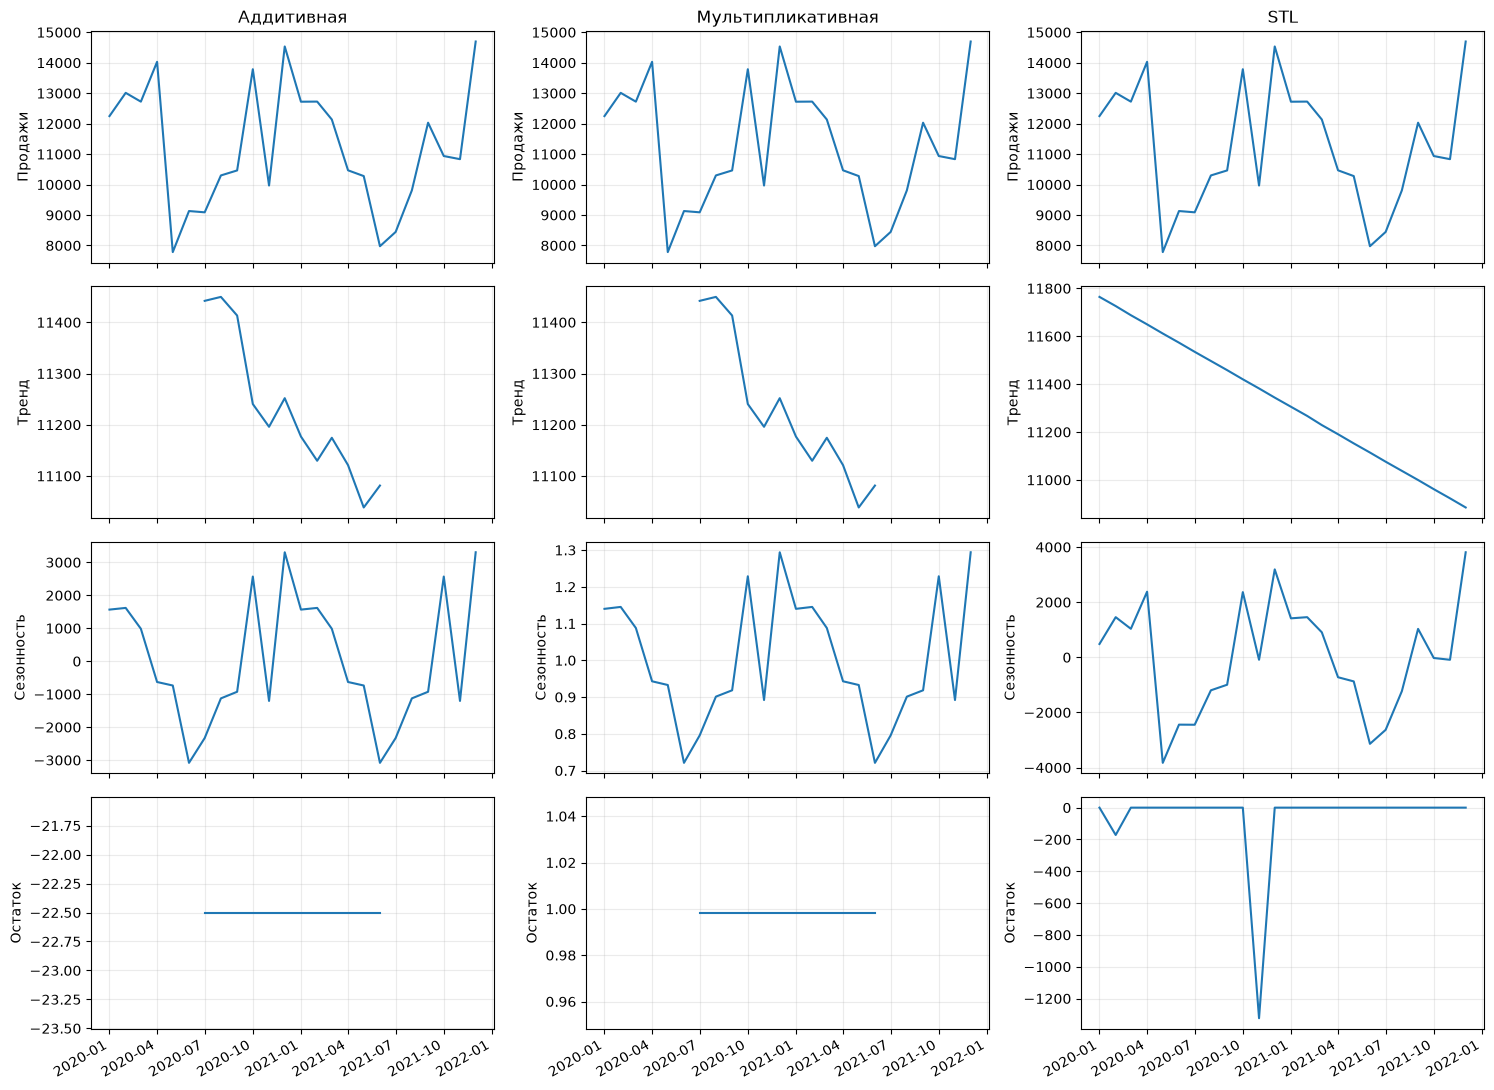

In [5]:
# Один и тот же период позволяет сопоставить три разложения.
additive = seasonal_decompose(series, model="additive", period=12)
multiplicative = seasonal_decompose(series, model="multiplicative", period=12)
stl = STL(series, period=12, robust=True).fit()

fig, axes = plt.subplots(4, 3, figsize=(15, 11), sharex=True)
for col, (name, result) in enumerate(
    [("Аддитивная", additive), ("Мультипликативная", multiplicative), ("STL", stl)]
):
    for row, (label, values) in enumerate(
        [
            ("Продажи", series),
            ("Тренд", result.trend),
            ("Сезонность", result.seasonal),
            ("Остаток", result.resid),
        ]
    ):
        axes[row, col].plot(series.index, values)
        axes[row, col].set_ylabel(label)

    axes[0, col].set_title(name)

    if col < 2:
        center = float(result.resid.mean())
        axes[3, col].set_ylim(
            center - (1 if col == 0 else 0.05), center + (1 if col == 0 else 0.05)
        )
        axes[3, col].ticklabel_format(axis="y", style="plain", useOffset=False)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 2.2. Спектр Фурье
FFT помогает найти повторяющиеся частоты, но не показывает, когда именно они появлялись. Перед расчётом уберу линейный тренд. Для поиска пиков использую окно Ханна: оно уменьшает искажения из-за стыка начала и конца ряда. Поскольку здесь всего 24 точки, частоты разделяются грубо; период около года - ориентир, а не точная оценка.

Отдельно восстановлю годовую гармонику из FFT без окна. Так можно получить разложение в исходных единицах: линейный тренд, годовая волна и всё, что они не объяснили.

,"Период, месяцев",Мощность
1,12.000,"149,886,004.111"
10,2.182,"47,126,500.034"
11,2.000,"40,732,772.442"
0,24.000,"35,400,345.680"
9,2.400,"31,832,658.529"


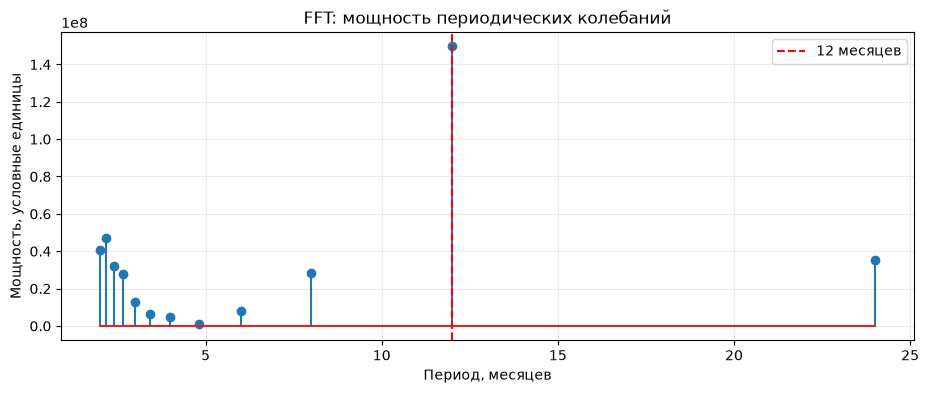

In [6]:
# Частота измеряется в циклах за месяц; обратная величина даёт период в месяцах.
detrended = signal.detrend(series.to_numpy())
frequencies = np.fft.rfftfreq(len(series), d=1)
power = np.abs(np.fft.rfft(detrended * np.hanning(len(series)))) ** 2

spectrum = pd.DataFrame({"Период, месяцев": 1 / frequencies[1:], "Мощность": power[1:]})
display(spectrum.sort_values("Мощность", ascending=False).head(5))

fig, ax = plt.subplots()
ax.stem(1 / frequencies[1:], power[1:])
ax.axvline(12, color="red", linestyle="--", label="12 месяцев")
ax.set(
    title="FFT: мощность периодических колебаний",
    xlabel="Период, месяцев",
    ylabel="Мощность, условные единицы",
)
ax.legend()
plt.show()

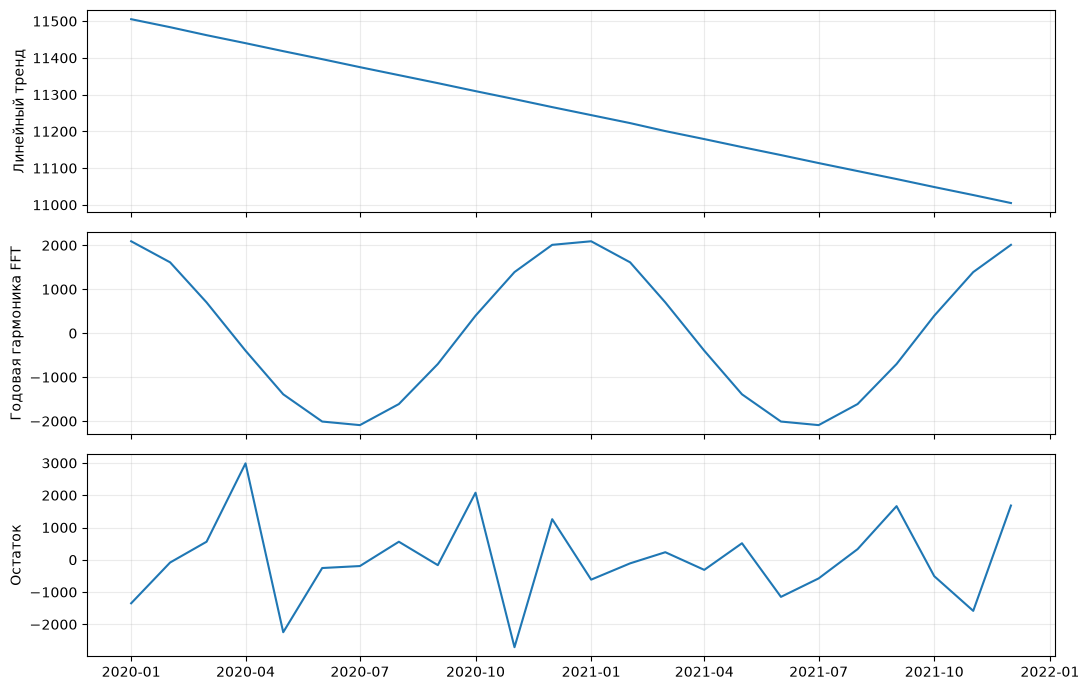

In [7]:
# Оставляем годовую частоту, а остальные относим к остатку.
coefficients = np.fft.rfft(detrended)
annual_bin = np.argmin(np.abs(frequencies - 1 / 12))
annual_coefficients = np.zeros_like(coefficients)
annual_coefficients[annual_bin] = coefficients[annual_bin]

fft_season = np.fft.irfft(annual_coefficients, n=len(series))
fft_trend = series.to_numpy() - detrended
fft_residual = detrended - fft_season

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, values, name in zip(
    axes,
    [fft_trend, fft_season, fft_residual],
    ["Линейный тренд", "Годовая гармоника FFT", "Остаток"],
):
    ax.plot(series.index, values)
    ax.set_ylabel(name)

plt.tight_layout()
plt.show()

### 2.3. Вейвлет-анализ
Вейвлет Морле сравнивает отдельные участки ряда с короткой волной. В отличие от FFT, он показывает и период, и расположение колебаний во времени. Цвет на карте ниже - квадрат модуля коэффициента.

У начала и конца ряда волне не хватает соседних наблюдений. Белые пунктирные линии отмечают примерную область краевых искажений (по масштабу Морле, √2 × масштаб). Для годовой волны на двухлетней истории почти нет надёжной внутренней области. Поэтому эта карта не доказывает, что годовая сезонность менялась со временем. CWT здесь - разложение по времени и масштабу, а не отдельная прогнозная модель.

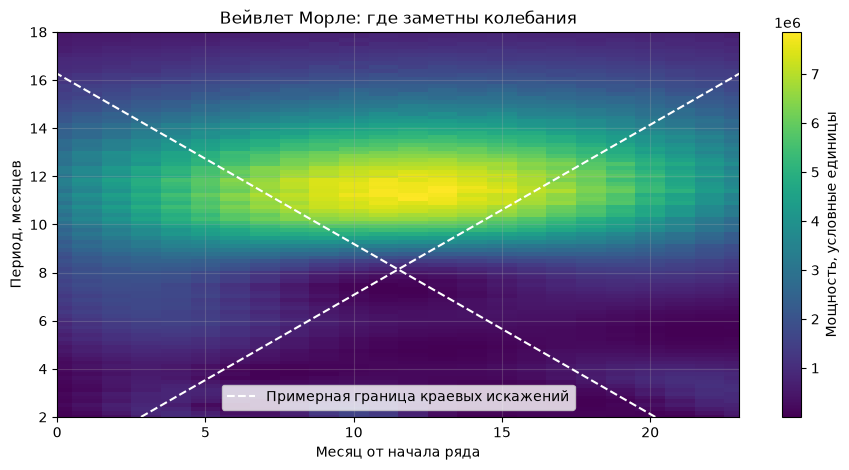

In [8]:
# Приводим масштабы к периодам, чтобы карту можно было читать в месяцах.
periods = np.linspace(2, 18, 100)
wavelet = "cmor1.5-1.0"
scales = pywt.central_frequency(wavelet) * periods

wave_coefficients, wave_frequencies = pywt.cwt(
    detrended, scales, wavelet, sampling_period=1
)
wave_power = np.abs(wave_coefficients) ** 2

fig, ax = plt.subplots(figsize=(11, 5))
mesh = ax.pcolormesh(
    np.arange(len(series)),
    1 / wave_frequencies,
    wave_power,
    shading="auto",
    cmap="viridis",
)

edge = np.sqrt(2) * scales
ax.plot(edge, periods, "w--", label="Примерная граница краевых искажений")
ax.plot(len(series) - 1 - edge, periods, "w--")

ax.set(
    xlim=(0, len(series) - 1),
    ylim=(2, 18),
    xlabel="Месяц от начала ряда",
    ylabel="Период, месяцев",
    title="Вейвлет Морле: где заметны колебания",
)
ax.legend(loc="lower center")
fig.colorbar(mesh, ax=ax, label="Мощность, условные единицы")
plt.show()

### Что дают эти методы
| Подход | Что удобно смотреть | Ограничение в этой работе |
|---|---|---|
| Аддитивное разложение | Сезонные прибавки и снижения в единицах продаж | Фиксированная сезонность; тренд отсутствует на краях |
| Мультипликативное | Сезонные изменения относительно уровня продаж | Нужны положительные значения; зависимость амплитуды от уровня здесь неочевидна |
| STL | Плавный тренд и сезонность с меньшим влиянием выбросов | На двух циклах может объяснить почти всё сезонностью и занизить остаток |
| FFT | Основные повторяющиеся периоды и восстановление годовой волны | Не локализует изменения во времени; чувствителен к длине ряда и обработке границ |
| Вейвлет Морле | Периоды на разных участках истории | Слишком мало данных для уверенных выводов о годовом цикле вне краевых эффектов |

**Вывод по второй части.** Календарные профили и FFT поддерживают выбор годового периода. Аддитивное разложение удобно тем, что все его компоненты читаются в исходных единицах. Убедительных оснований считать сезонность пропорциональной уровню продаж нет. У классических разложений остаток почти постоянный: после потери краёв остаётся лишь по одному наблюдению на каждый месяц, и сезонная компонента поглощает почти все различия. Это следствие короткой истории, а не идеальная точность метода. STL хорошо показывает форму, но его маленький остаток на двух годах нельзя принимать за доказательство хорошего прогноза. Вейвлет-карта полезна для наглядности, однако короткая история сильно ограничивает её интерпретацию. Для SARIMAX проверю сезонность с периодом 12.

## 3. Подбор ARIMA и SARIMAX
Сначала посмотрю на стационарность и корреляции. ADF проверяет гипотезу о единичном корне, KPSS - о стационарности относительно постоянного уровня. На 24 наблюдениях оба теста неточны, особенно при сезонности, поэтому их результат не заменяет проверку прогноза.

,Ряд,ADF p,KPSS p,Примечание
0,Исходный ряд,0.027,0.100,adfuller currently returns a plain tuple whose...
1,Первая разность,0.000,0.100,adfuller currently returns a plain tuple whose...


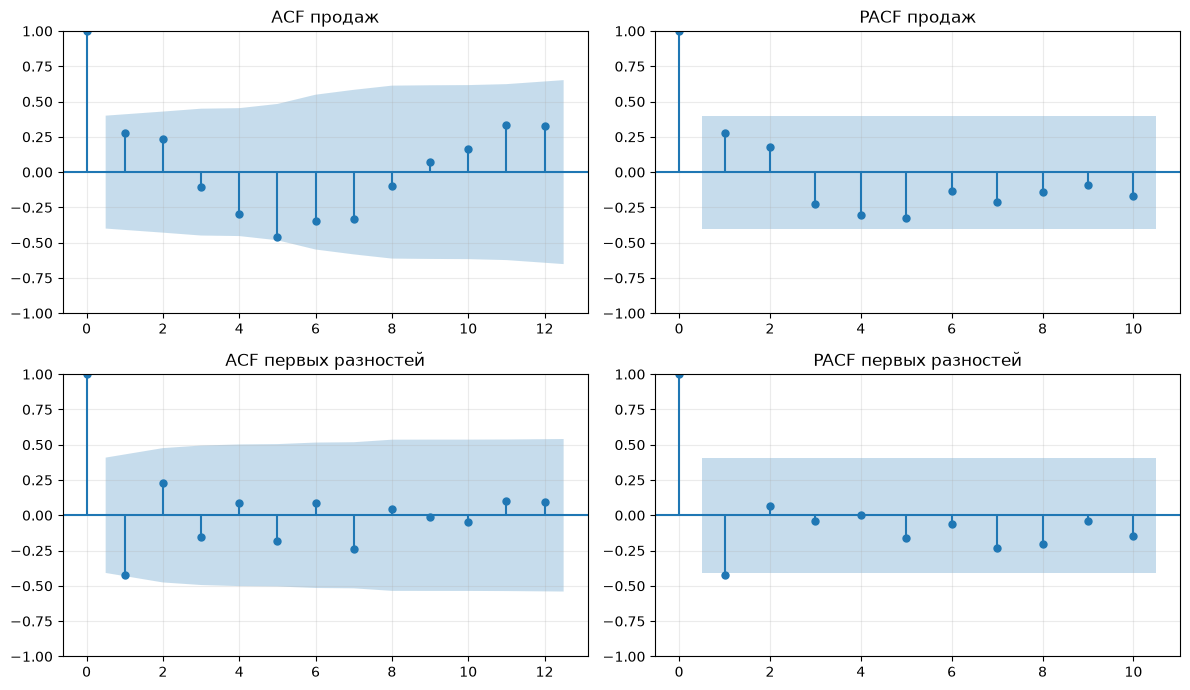

In [9]:
# Разности помогают понять, требуется ли модели удалять меняющийся уровень.
import warnings

stationarity = []
for name, values in [
    ("Исходный ряд", series),
    ("Первая разность", series.diff().dropna()),
]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        adf = adfuller(values, maxlag=3, autolag="AIC")
        kp = kpss(values, regression="c", nlags="auto")

    stationarity.append(
        {
            "Ряд": name,
            "ADF p": adf[1],
            "KPSS p": kp[1],
            "Примечание": "; ".join(str(w.message) for w in caught),
        }
    )

display(pd.DataFrame(stationarity))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, values in enumerate([series, series.diff().dropna()]):
    plot_acf(values, lags=12, ax=axes[row, 0])
    plot_pacf(values, lags=10, method="ywm", ax=axes[row, 1])
    axes[row, 0].set_title(["ACF продаж", "ACF первых разностей"][row])
    axes[row, 1].set_title(["PACF продаж", "PACF первых разностей"][row])

plt.tight_layout()
plt.show()

### Какие варианты сравниваю
На первых 24 месяцах ADF даёт p около 0,027, а KPSS не отвергает стационарность (его p находится у верхней границы таблицы, 0,10). Явного требования брать d=1 нет. Тем не менее оставлю обе возможности: на коротком сезонном ряде решение по одному тесту ненадёжно.

Из-за короткой истории не буду перебирать большие порядки. Для ARIMA проверю `(p,d,q)` из небольшого набора: `(0,0,0)`, `(1,0,0)`, `(2,0,0)`, `(0,0,1)`, `(1,0,1)`, `(0,1,0)`, `(1,1,0)`, `(0,1,1)`. Корреляции служат ориентиром для небольших p и q, а d=0 и d=1 позволяют проверить необходимость разности.

У SARIMAX добавлю один из вариантов `(P,D,Q,12)`: `(1,0,0,12)`, `(0,0,1,12)` или `(0,1,0,12)`, а также `Promotion` и `HolidayMonth`. При D=1 оставляю только `Promotion`: годовая разность обнуляет повторяющийся декабрьский `HolidayMonth`, и его отдельный коэффициент определить нельзя. Декабрьский подъём в этом случае учитывается через прошлогодние продажи. Все модели содержат константу; при разностях она допускает дрейф. ARIMA рассчитывается тем же классом `SARIMAX`, но без сезонной части и внешних признаков: это математически та же ARIMA. Так настройки оценивания одинаковы.

Сравнение с внешними признаками **условное**: предполагаю, что календарь праздников и план акций известны на дату прогноза. В файле есть только фактические отметки, подтвердить наличие такого плана нельзя. Если акции заранее неизвестны, точность SARIMAX из этой работы нельзя обещать.

Выбираю параметры по средней MSE на трёх временных срезах. Их проверочные отрезки перекрываются: это повторные прогнозы, а не независимые наблюдения. Кандидаты без сходимости исключаются, предупреждения сохраняются в таблице. Тестовый 2023 год в подборе не участвует.

In [10]:
# Расчёт может занять несколько минут; в функцию передаются только данные до теста.
selection, best, validation_predictions = select_models(train, x.iloc[:36])
display(selection.drop(columns="Предупреждения").reset_index(drop=True))

issues = selection.loc[
    selection["Предупреждения"].ne(""),
    ["Модель", "order", "seasonal_order", "Сходимость", "Предупреждения"],
]
display(issues)

display(
    pd.DataFrame(
        [
            {"Модель": family, "order": key[1], "seasonal_order": key[2]}
            for family, key in best.items()
        ]
    )
)

,Модель,order,seasonal_order,MSE,R²,Сходимость
0,SARIMAX,"(1, 1, 0)","(0, 1, 0, 12)","707,367.563",0.864,True
1,SARIMAX,"(0, 1, 1)","(0, 1, 0, 12)","822,049.464",0.842,True
2,SARIMAX,"(0, 0, 0)","(0, 1, 0, 12)","877,871.614",0.831,True
3,SARIMAX,"(1, 0, 0)","(0, 1, 0, 12)","884,553.340",0.830,True
4,SARIMAX,"(0, 0, 1)","(0, 1, 0, 12)","900,361.678",0.827,True
5,SARIMAX,"(0, 1, 0)","(0, 1, 0, 12)","918,370.452",0.823,True
6,SARIMAX,"(1, 0, 1)","(0, 1, 0, 12)","925,596.992",0.822,True
7,SARIMAX,"(2, 0, 0)","(0, 1, 0, 12)","926,617.961",0.822,True
8,SARIMAX,"(0, 1, 1)","(1, 0, 0, 12)","1,010,742.860",0.805,True
9,SARIMAX,"(1, 0, 0)","(1, 0, 0, 12)","1,121,807.433",0.784,True


,Модель,order,seasonal_order,Сходимость,Предупреждения
31,SARIMAX,"(0, 1, 1)","(0, 1, 0, 12)",True,Non-invertible starting MA parameters found. U...
15,SARIMAX,"(2, 0, 0)","(0, 0, 1, 12)",True,Too few observations to estimate starting para...
9,SARIMAX,"(0, 0, 0)","(0, 0, 1, 12)",True,Too few observations to estimate starting para...
18,SARIMAX,"(0, 0, 1)","(0, 0, 1, 12)",True,Too few observations to estimate starting para...
21,SARIMAX,"(1, 0, 1)","(0, 0, 1, 12)",True,Too few observations to estimate starting para...
12,SARIMAX,"(1, 0, 0)","(0, 0, 1, 12)",True,Too few observations to estimate starting para...
30,SARIMAX,"(0, 1, 1)","(0, 0, 1, 12)",True,Too few observations to estimate starting para...
24,SARIMAX,"(0, 1, 0)","(0, 0, 1, 12)",True,Too few observations to estimate starting para...
27,SARIMAX,"(1, 1, 0)","(0, 0, 1, 12)",True,Too few observations to estimate starting para...


,Модель,order,seasonal_order
0,ARIMA,"(0, 0, 1)","(0, 0, 0, 0)"
1,SARIMAX,"(1, 1, 0)","(0, 1, 0, 12)"


In [11]:
# После выбора параметров используем все 36 обучающих месяцев.
# Одинаковый начальный отрезок для условного правдоподобия обеих моделей.
likelihood_start = max(key[1][1] + key[2][1] * key[2][3] for key in best.values())
fitted_models, training_rows = {}, []
for family, key in best.items():
    model, message = fit_model(
        train,
        x.iloc[:36] if family == "SARIMAX" else None,
        key[1],
        key[2],
        likelihood_start=likelihood_start,
    )
    assert model.mle_retvals["converged"], f"Не сошлась итоговая {family}"

    fitted_models[family] = model
    training_rows.append(
        {
            "Модель": family,
            "AIC": model.aic,
            "BIC": model.bic,
            "Число параметров": len(model.params),
            "Месяцев в правдоподобии": model.nobs_effective,
            "Предупреждения": message,
        }
    )

information = pd.DataFrame(training_rows).set_index("Модель")
display(information)

for family, model in fitted_models.items():
    display(Markdown(f"**Оценки коэффициентов {family}**"))
    display(
        pd.DataFrame({"Коэффициент": model.params, "Стандартная ошибка": model.bse})
    )

,AIC,BIC,Число параметров,Месяцев в правдоподобии,Предупреждения
Модель,,,,,
ARIMA,97.152,100.559,3,23,
SARIMAX,73.475,78.017,4,23,


**Оценки коэффициентов ARIMA**

,Коэффициент,Стандартная ошибка
intercept,11.664,0.704
ma.L1,0.617,0.141
sigma2,3.081,1.205


**Оценки коэффициентов SARIMAX**

,Коэффициент,Стандартная ошибка
intercept,0.046,0.275
Promotion,2.602,0.467
ar.L1,-0.441,0.275
sigma2,0.999,0.457


AIC и BIC сравниваю по условному правдоподобию на одном и том же отрезке: с февраля 2021 по декабрь 2022 года, всего 23 месяца. Первые 13 месяцев у обеих моделей служат историей для фильтра. Параметры заново оцениваются с максимизацией суммы логарифмов плотностей одношагового прогноза именно на этих 23 месяцах. Поэтому здесь не просто отбрасываются слагаемые у уже обученных моделей.

Обе модели оценивают исходные уровни продаж в тысячах единиц. Разности задаются внутри модели состояния, а не применяются к данным перед расчётом правдоподобия. Благодаря этому сравниваются плотности одних и тех же наблюдений при одной и той же доступной истории.

Критерии рассчитываются как AIC = −2 ln L + 2k и BIC = −2 ln L + k ln n, где k включает все оцениваемые коэффициенты и дисперсию ошибки, n = 23. Меньшее значение предпочтительнее. Это сравнение качества описания обучающей истории с поправкой на сложность; точность прогноза отдельно проверяется на 2023 году.

**Вывод по третьей части.** На проверочных отрезках лучше всего показали себя ARIMA(0, 0, 1) и SARIMAX(1, 1, 0) с сезонной частью (0, 1, 0, 12). У ARIMA средняя квадратичная ошибка составила 5 061 998, у SARIMAX - 707 368. Разница заметная: учёт годового цикла и акций помог точнее предсказать продажи. Пока предпочтительнее SARIMAX, но окончательно сравнить модели можно будет по результатам на 2023 году.

После переоценки по общему условному правдоподобию AIC у ARIMA равен 97,152, у SARIMAX - 73,475; BIC - 100,559 и 78,017 соответственно. Оба критерия поддерживают SARIMAX: улучшение описания ряда компенсирует дополнительный параметр.

## 4. Качество и горизонт прогноза
### Что считать приемлемым качеством
Численный порог в задании не указан. Для этой работы заранее принимаю условное правило: R² не ниже нуля, MSE не хуже сезонного повтора («как в том же месяце год назад»), а RMSE не больше 20% среднего объёма обучающих продаж. Это рабочий критерий для сравнения, а не согласованная бизнесом допустимая ошибка.

Проверяю горизонты от 3 до 12 месяцев: на одной точке R² не определён, на двух он слишком неустойчив. Для каждого горизонта считаю качество всего отрезка от первого месяца до h. Выбираю самый длинный горизонт, на котором весь прогноз от первого месяца до h проходит эти пороги. Оценки более коротких отрезков показываю отдельно: они не запрещают выбрать длинный горизонт. Вначале определяю его на валидации, затем отдельно проверяю на тесте. На 10-12-м шагах валидации остаётся только один прогноз: уверенность в длинном горизонте ниже.

Дальше 12 месяцев качество по этому разбиению проверить нельзя. Поэтому «максимальный» здесь означает максимальный в доступной проверке, а не гарантированную дальность на любые будущие годы.

In [12]:
# Горизонт выбирается до просмотра тестовых ошибок.
validation_horizons, chosen_horizons = {}, {}
for family, key in best.items():
    table = horizon_quality(validation_predictions[key])
    validation_horizons[family] = table
    chosen_horizons[family] = supported_horizon(table)

    display(
        Markdown(
            f"**{family}: валидация, выбранный горизонт {chosen_horizons[family]}"
            " мес.**"
        )
    )
    display(table)

**ARIMA: валидация, выбранный горизонт 0 мес.**

,MSE,R²,MSE сезонного повтора,Относительная RMSE,Приемлемо,Число прогнозов,Прогнозов на шаге h
Горизонт,,,,,,,
3,"6,220,039.124",0.059,"3,067,917.667",0.219,False,9,3
4,"5,175,781.538",0.051,"2,446,366.000",0.199,False,12,3
5,"4,575,702.860",0.058,"2,499,107.067",0.188,False,15,3
6,"5,322,901.064",0.050,"2,138,596.500",0.203,False,18,3
7,"5,023,008.712",0.050,"1,954,855.450",0.197,False,20,2
8,"4,593,397.288",0.050,"2,047,267.364",0.188,False,22,2
9,"4,891,918.292",0.053,"1,914,991.833",0.194,False,24,2
10,"4,697,382.795",0.054,"1,839,746.400",0.190,False,25,1
11,"4,527,197.961",0.052,"1,805,774.769",0.186,False,26,1


**SARIMAX: валидация, выбранный горизонт 12 мес.**

,MSE,R²,MSE сезонного повтора,Относительная RMSE,Приемлемо,Число прогнозов,Прогнозов на шаге h
Горизонт,,,,,,,
3,"783,042.105",0.882,"3,067,917.667",0.078,True,9,3
4,"671,098.938",0.877,"2,446,366.000",0.072,True,12,3
5,"608,096.460",0.875,"2,499,107.067",0.068,True,15,3
6,"668,782.646",0.881,"2,138,596.500",0.071,True,18,3
7,"706,647.795",0.866,"1,954,855.450",0.073,True,20,2
8,"799,140.994",0.835,"2,047,267.364",0.078,True,22,2
9,"777,147.986",0.850,"1,914,991.833",0.077,True,24,2
10,"751,180.490",0.849,"1,839,746.400",0.076,True,25,1
11,"729,106.832",0.847,"1,805,774.769",0.075,True,26,1


In [13]:
# Оба прогноза стартуют в декабре 2022 года и не обновляются тестовыми продажами.
predictions, intervals, test_rows = {}, {}, []
for family, model in fitted_models.items():
    future_x = x.iloc[36:][model.model.exog_names] if family == "SARIMAX" else None
    forecast = model.get_forecast(len(test), exog=future_x)
    predictions[family] = forecast.predicted_mean * 1000
    intervals[family] = forecast.conf_int(alpha=0.05) * 1000
    test_rows.append({"Модель": family, **metrics(test, predictions[family])})

naive = pd.Series(train.iloc[-12:].to_numpy(), index=test.index)
test_rows.append({"Модель": "Сезонный повтор", **metrics(test, naive)})

quality = pd.DataFrame(test_rows).set_index("Модель").join(information[["AIC", "BIC"]])
display(quality)

forecast_table = pd.DataFrame({"Факт": test, "Сезонный повтор": naive, **predictions})
for family in fitted_models:
    forecast_table[f"{family}: нижняя 95%"] = intervals[family].iloc[:, 0]
    forecast_table[f"{family}: верхняя 95%"] = intervals[family].iloc[:, 1]

display(forecast_table)

,MSE,R²,AIC,BIC
Модель,,,,
ARIMA,"4,972,973.857",-0.075,97.152,100.559
SARIMAX,"1,034,222.961",0.776,73.475,78.017
Сезонный повтор,"2,757,115.250",0.404,NaN,NaN


,Факт,Сезонный повтор,ARIMA,SARIMAX,ARIMA: нижняя 95%,ARIMA: верхняя 95%,SARIMAX: нижняя 95%,SARIMAX: верхняя 95%
2023-01-01,"13,904.000","16,623.000","14,009.571","15,029.296","10,569.251","17,449.891","13,069.903","16,988.689"
2023-02-01,"13,901.000","14,336.000","11,663.689","15,364.232","7,620.970","15,706.408","13,119.464","17,609.000"
2023-03-01,"13,534.000","13,023.000","11,663.689","14,088.557","7,620.970","15,706.408","11,401.803","16,775.312"
2023-04-01,"12,048.000","11,537.000","11,663.689","12,632.334","7,620.970","15,706.408","9,643.955","15,620.713"
2023-05-01,"12,949.000","8,800.000","11,663.689","12,530.168","7,620.970","15,706.408","9,237.518","15,822.818"
2023-06-01,"9,104.000","8,273.000","11,663.689","9,433.077","7,620.970","15,706.408","5,874.509","12,991.645"
2023-07-01,"10,042.000","9,199.000","11,663.689","10,391.362","7,620.970","15,706.408","6,580.276","14,202.447"
2023-08-01,"11,566.000","12,043.000","11,663.689","13,267.361","7,620.970","15,706.408","9,221.617","17,313.105"
2023-09-01,"11,759.000","11,892.000","11,663.689","13,148.486","7,620.970","15,706.408","8,880.075","17,416.897"
2023-10-01,"11,890.000","11,121.000","11,663.689","12,409.556","7,620.970","15,706.408","7,929.906","16,889.205"


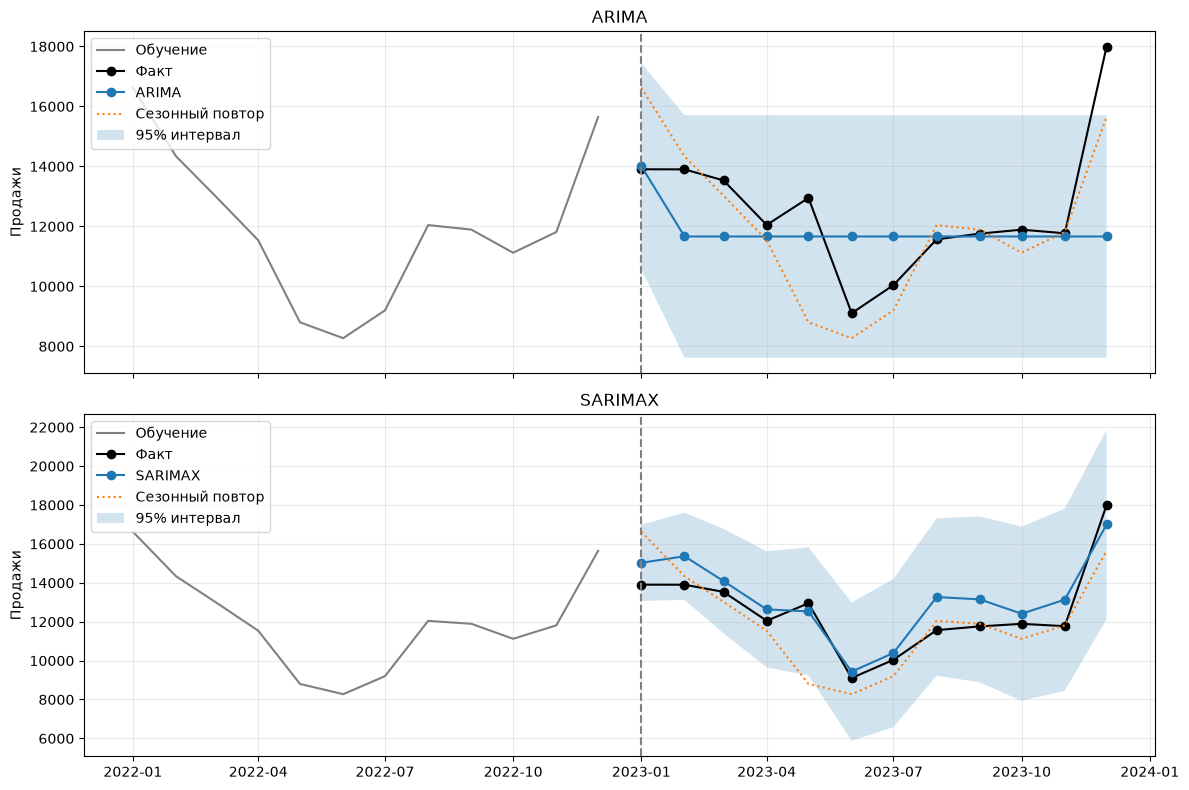

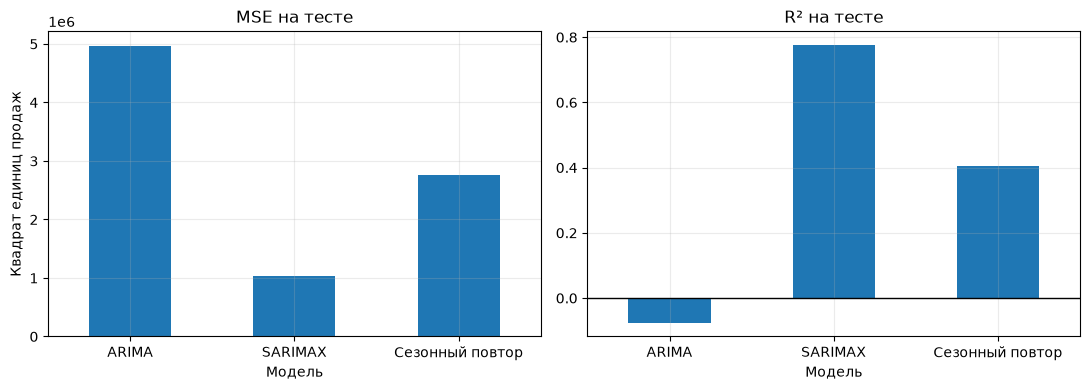

In [14]:
# Интервалы условны относительно модели и переданного календаря акций.
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, family in zip(axes, fitted_models):
    ax.plot(train.iloc[-12:], color="gray", label="Обучение")
    ax.plot(test, color="black", marker="o", label="Факт")
    ax.plot(predictions[family], marker="o", label=family)
    ax.plot(naive, linestyle=":", label="Сезонный повтор")

    ax.fill_between(
        test.index,
        intervals[family].iloc[:, 0],
        intervals[family].iloc[:, 1],
        alpha=0.2,
        label="95% интервал",
    )

    ax.axvline(test.index[0], color="gray", linestyle="--")
    ax.set(title=family, ylabel="Продажи")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
quality.MSE.plot.bar(
    ax=axes[0], rot=0, title="MSE на тесте", ylabel="Квадрат единиц продаж"
)
quality["R²"].plot.bar(ax=axes[1], rot=0, title="R² на тесте")
axes[1].axhline(0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

**ARIMA: качество по длине тестового прогноза**

,MSE,R²,MSE сезонного повтора,Относительная RMSE,Приемлемо,Число прогнозов,Прогнозов на шаге h
Горизонт,,,,,,,
3,"2,838,257.383",-93.052,"2,614,435.667",0.146,False,3,1
4,"2,165,616.848",-2.703,"2,026,107.000",0.128,False,4,1
5,"2,062,898.550",-3.183,"5,063,725.800",0.125,False,5,1
6,"2,811,083.091",0.003,"4,334,865.000",0.146,True,6,1
7,"2,785,196.072",0.130,"3,817,119.857",0.145,True,7,1
8,"2,438,239.447",0.143,"3,368,421.000",0.136,True,8,1
9,"2,168,333.315",0.147,"2,996,117.444",0.128,True,9,1
10,"1,956,621.668",0.147,"2,755,641.800",0.122,True,10,1
11,"1,779,774.435",0.149,"2,505,289.273",0.116,True,11,1


**SARIMAX: качество по длине тестового прогноза**

,MSE,R²,MSE сезонного повтора,Относительная RMSE,Приемлемо,Число прогнозов,Прогнозов на шаге h
Горизонт,,,,,,,
3,"1,238,291.298",-40.034,"2,614,435.667",0.097,False,3,1
4,"1,014,080.030",-0.734,"2,026,107.000",0.087,False,4,1
5,"846,348.075",-0.716,"5,063,725.800",0.080,False,5,1
6,"723,338.655",0.743,"4,334,865.000",0.074,True,6,1
7,"637,440.779",0.801,"3,817,119.857",0.069,True,7,1
8,"919,589.301",0.677,"3,368,421.000",0.083,True,8,1
9,"1,031,931.784",0.594,"2,996,117.444",0.088,True,9,1
10,"955,732.428",0.583,"2,755,641.800",0.085,True,10,1
11,"1,037,649.017",0.504,"2,505,289.273",0.088,True,11,1


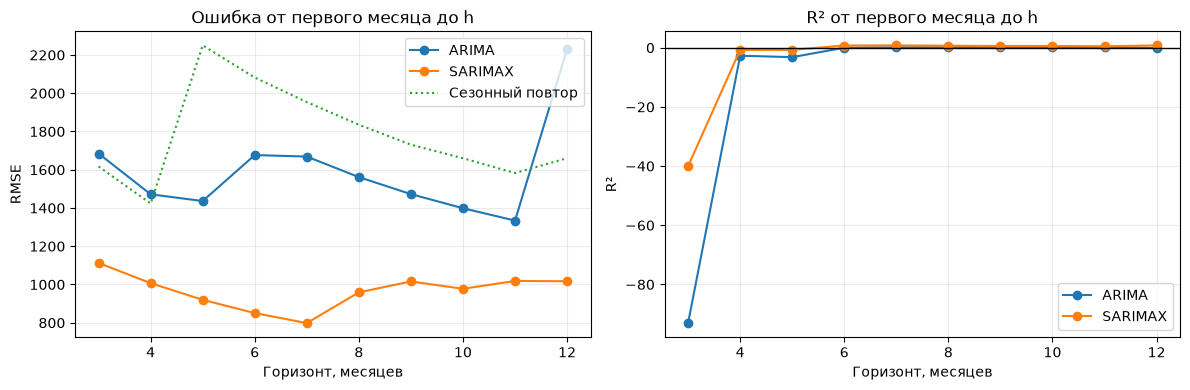

,"Горизонт по валидации, мес.",Подтверждён на тесте
Модель,,
ARIMA,NaN,False
SARIMAX,12.000,True


In [15]:
# На тесте только проверяем ранее выбранный горизонт, не подбираем параметры заново.
test_horizons = {}
for family, pred in predictions.items():
    folds = pd.DataFrame(
        {
            "h": np.arange(1, 13),
            "actual": test.to_numpy(),
            "pred": pred.to_numpy(),
            "naive": naive.to_numpy(),
            "scale": train.mean(),
        }
    )
    test_horizons[family] = horizon_quality(folds)
    display(Markdown(f"**{family}: качество по длине тестового прогноза**"))
    display(test_horizons[family])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for family, table in test_horizons.items():
    axes[0].plot(table.index, np.sqrt(table.MSE), marker="o", label=family)
    axes[1].plot(table.index, table["R²"], marker="o", label=family)

axes[0].plot(
    table.index,
    np.sqrt(table["MSE сезонного повтора"]),
    linestyle=":",
    label="Сезонный повтор",
)

axes[0].set(
    title="Ошибка от первого месяца до h", xlabel="Горизонт, месяцев", ylabel="RMSE"
)
axes[1].set(title="R² от первого месяца до h", xlabel="Горизонт, месяцев", ylabel="R²")
axes[1].axhline(0, color="black", linewidth=1)

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

# На тесте подтверждаем только горизонт, выбранный по валидации.
horizon_rows = []
for family, h in chosen_horizons.items():
    confirmed = h > 0 and bool(test_horizons[family].loc[h, "Приемлемо"])
    horizon_rows.append(
        {
            "Модель": family,
            "Горизонт по валидации, мес.": h if h else None,
            "Подтверждён на тесте": confirmed,
        }
    )
display(pd.DataFrame(horizon_rows).set_index("Модель"))

**Вывод по четвёртой части.** На тестовом 2023 году SARIMAX оказалась точнее ARIMA: MSE составила 1 034 223 против 4 972 974, а R² - 0,776 против −0,075. SARIMAX также обошла прогноз по продажам того же месяца прошлого года, у которого MSE равна 2 757 115.

На валидации для SARIMAX выбран горизонт 12 месяцев. На тесте он подтвердился: R² положительный, ошибка ниже сезонного повтора, а RMSE составляет около 8,8% среднего объёма обучающих продаж при пороге 20%. Это максимальный горизонт, который можно проверить при выбранном разбиении данных. У ARIMA на валидации ни один из рассмотренных горизонтов не прошёл принятые пороги.

На первых трёх-пяти тестовых месяцах R² у SARIMAX отрицательный. В январе-марте продажи почти не менялись, поэтому даже сравнительно небольшая ошибка сильно снижает эту метрику. Это ограничение точности на коротких отрезках, но оно не отменяет результат оценки всего годового прогноза. Для срока больше 12 месяцев качество в работе не проверялось.

## 5. Остатки и итоговый выбор
Хороший прогноз не означает, что модель описала всё. Проверю ошибки внутри обучающей истории: похожи ли они на нормальное распределение, осталась ли в них зависимость от прошлых месяцев и меняется ли разброс.

Использую стандартизованные ошибки одношагового прогноза из фильтра модели. У обеих моделей убираю первые 13 месяцев (один год и ещё один месяц для обычной разности), где сильнее влияет инициализация, и сравниваю один и тот же оставшийся период. Для нормальности беру тест Жарка-Бера и Q-Q график, для автокорреляции - тест Льюнга-Бокса и ACF, для постоянства дисперсии - ARCH-LM и тест разницы дисперсий в начале и конце отрезка. ARCH проверяет зависимость квадратов ошибок, а не все возможные виды неодинакового разброса.

Уровень значимости 0,05. Большое p-значение означает, что оснований отвергнуть гипотезу не хватило; на двух десятках ошибок это не доказательство, что с моделью всё идеально.

In [16]:
# Для Льюнга-Бокса учитываем число авторегрессионных и MA-параметров.
residuals, diagnostic_rows = {}, []
for family, model in fitted_models.items():
    residual = pd.Series(
        model.filter_results.standardized_forecasts_error[0], index=train.index
    ).iloc[13:]
    assert np.isfinite(residual).all()
    residuals[family] = residual

    key = best[family]
    degrees = key[1][0] + key[1][2] + key[2][0] + key[2][2]

    lb = acorr_ljungbox(residual, lags=[6, 12], model_df=degrees, return_df=True)
    jb = stats.jarque_bera(residual)
    arch = het_arch(residual, nlags=3, ddof=degrees)

    # Сопоставляем первую и последнюю трети одного и того же отрезка остатков.
    third = len(residual) // 3
    first, last = residual.iloc[:third], residual.iloc[-third:]
    variance_test = stats.levene(first, last, center="median")

    diagnostic_rows.append(
        {
            "Модель": family,
            "Ошибок": len(residual),
            "Жарк-Бера p": jb.pvalue,
            "Льюнг-Бокс 6 p": lb.loc[6, "lb_pvalue"],
            "Льюнг-Бокс 12 p": lb.loc[12, "lb_pvalue"],
            "ARCH-LM p": arch[1],
            "Левен p": variance_test.pvalue,
        }
    )

diagnostics = pd.DataFrame(diagnostic_rows).set_index("Модель")
display(diagnostics)

/private/tmp/retail-lab-venv/lib/python3.14/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,Ошибок,Жарк-Бера p,Льюнг-Бокс 6 p,Льюнг-Бокс 12 p,ARCH-LM p,Левен p
Модель,,,,,,
ARIMA,23,0.520,0.008,0.000,0.213,0.588
SARIMAX,23,0.590,0.119,0.164,0.840,0.694


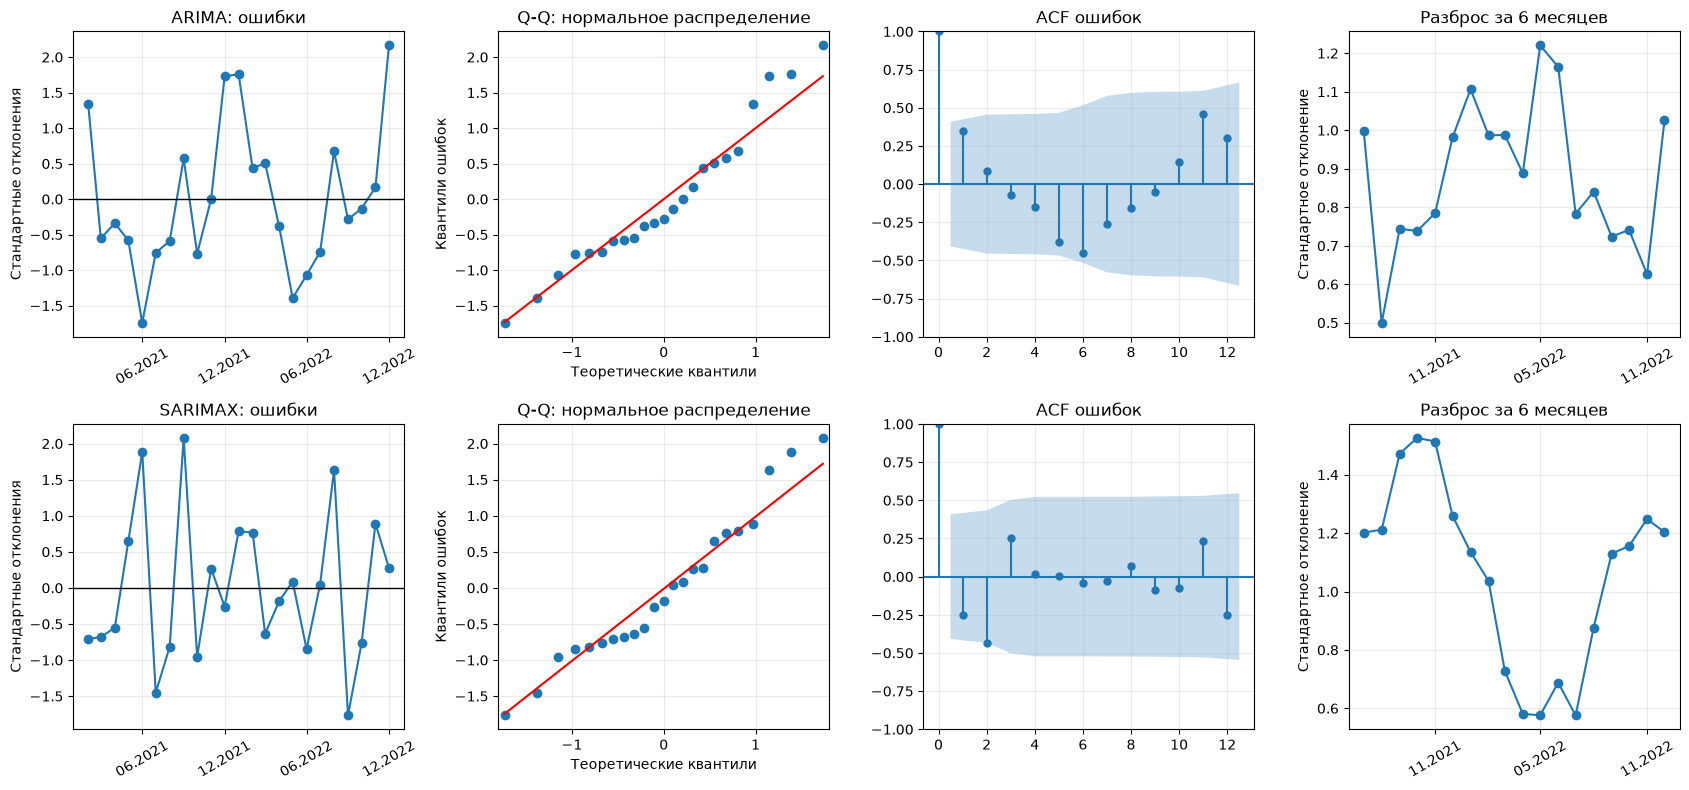

In [17]:
# Визуальная проверка нужна вместе с тестами: выборка остатков небольшая.
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for row, (family, residual) in enumerate(residuals.items()):
    axes[row, 0].plot(residual, marker="o")
    axes[row, 0].axhline(0, color="black", linewidth=1)
    axes[row, 0].set(title=f"{family}: ошибки", ylabel="Стандартные отклонения")

    qqplot(residual, line="s", ax=axes[row, 1])
    axes[row, 1].set(
        title="Q-Q: нормальное распределение",
        xlabel="Теоретические квантили",
        ylabel="Квантили ошибок",
    )

    plot_acf(residual, lags=12, ax=axes[row, 2])
    axes[row, 2].set_title("ACF ошибок")

    axes[row, 3].plot(residual.rolling(6).std(), marker="o")
    axes[row, 3].set(title="Разброс за 6 месяцев", ylabel="Стандартное отклонение")

    for col in (0, 3):
        axes[row, col].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
        axes[row, col].xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
        axes[row, col].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Вывод по пятой части.** В остатках ARIMA сохранилась автокорреляция: тест Льюнга-Бокса дал p < 0,05 и на 6, и на 12 лагах. Значит, модель не уловила часть повторяющихся изменений продаж. У SARIMAX эти тесты не выявили значимой автокорреляции.

Тесты Жарка-Бера, ARCH-LM и Левена для обеих моделей дали p > 0,05. По ним нет оснований отвергать нормальность и постоянство дисперсии ошибок. При этом осталось всего 23 наблюдения остатков, поэтому результаты тестов нельзя считать окончательным доказательством.

**Итог.** Из двух моделей предпочтительнее SARIMAX: у неё ниже ошибка и на валидации, и на тесте, оба информационных критерия ниже, а в остатках меньше признаков неучтённой зависимости. Этот результат получен при условии, что план акций известен заранее. Подтверждённый горизонт в этой проверке составляет 12 месяцев. Хороший результат за один год ещё не гарантирует такую же точность в следующие годы.